<a href="https://colab.research.google.com/github/makenzieearle/Modeling-Probability-of-the-Schrodinger-Equation/blob/main/Copy_of_06_1qubit_gates_and_noise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6. 1-Qubit Gates and Noise

## Objectives
* Understand how to decompose 1-qubit gates into different gate sets
* Use gate identities to transpile and simplify circuits
* Learn how noise affects the accuracy of results
* Run a circuit under a realistic noise model

## Part 1 — Decompositions & Identities

### Gate Identities and Decomposition

In the lectures on 1-qubit gates, you were introduced to a number of different gates that commonly arise in quantum computing. Some of them, like the $X,Y,Z,$ and $H$ are very efficient for doing theoretical work with, but are potentially difficult to implement with real hardware. Others, like $R_X,R_Y,S$ are easier to implement on hardware, but aren't as nice for theoretical work.  Therefore it would be nice to know that regardless of what choice of gates we write our circuits in, they can be reasonably translated to a real machine. This is the purpose of <b>transpilers</b>.

Transpilers take quantum circuits written with a broad range of flexible gates, and then decompose them using some gate set usable on the device.  In the lecture, we were introduced to one such prescription, <b>ZYZ decomposition</b>:

$$U = e^{i\alpha}\, R_z(\theta_2)\, R_y(\theta_1)\, R_z(\theta_0)$$

This prescription can be used to take any 1-qubit unitary and decompose it into at most 3 gates.  If your hardware had access to a different set of gates besides $R_X,R_Y,R_Z$, then this decomposition wouldn't necessarily help and others must be used.

Another function that most transpilers perform is to attempt to optimize the number of gates used in order to reduce noise.  For example: During decomposing a set of gates, a transpiler might come across the set of gates $H Z H$.  As you will learn, this is equivalent to a single $X$ gate.  If the hardware being used has access to the $X$ gate, the transpiler is likely to replace $HZH$ by $X$. If instead, you were to put an $X$ gate into code for use with hardware that has $H,Z$ but no $X$, the transpiler would do this replacement as part of its decomposition.

In this lab, you will undertake to "transpile" a few circuits, along the way learning some 1-qubit gate identities that are useful. As a first step, the table below defines all the gates we will consider:

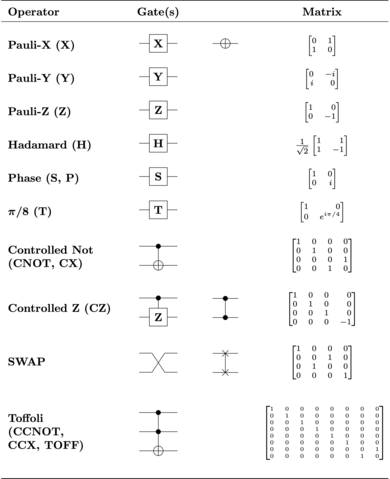

In addition to these, there is one other "gate" $\mathbb{1}=\begin{pmatrix}1 & 0\\0 & 1\end{pmatrix}$ which can be removed from any circuit, because it corresponds to leaving the qubit alone.

### 2 gate identities

For our first identities, you should try and compute the following circuits, and see which gate in the table they correspond to:

* $X X$

* $S S$

<div class="alert alert-info">

**Reading order matters.** When written as a *circuit*, gates are read left to right, but as *matrices* you multiply them in the reverse order: the circuit $AB$ is the matrix $\hat{A}\,\hat{B}$, applied to a state as $\hat{A}\hat{B}\,|\psi\rangle$.

</div>


In [5]:
x=X@X
s=S@S
print(x)
print(s)

[[1 0]
 [0 1]]
[[ 1.+0.j  0.+0.j]
 [ 0.+0.j -1.+0.j]]


Hopefully you didn't find that too painful.  For the rest of this lab, you won't be asked to do any more matrix multiplication by hand.

From your calculations, you should have found that $X X=\mathbb{1}$ and $S S=Z$. From this, you could conclude that if these arise in a circuit, the identities can be used to reduce the gate cost (total number of gates).

In the next cell, let's introduce python code that define these matrices for us, such that we can do the matrix multiplication numerically.

In [2]:
import numpy as np

X = np.matrix([[0,1],[1,0]])
Y = np.matrix([[0,-1j],[1j,0]])
Z = np.matrix([[1,0],[0,-1]])
H = 1/np.sqrt(2)*np.matrix([[1,1],[1,-1]])
S = np.matrix([[1,0],[0,1j]])
T = np.matrix([[1,0],[0,np.exp(1j*np.pi/4)]])

In python, the way to multiply two matrices $A,B$ to obtain a matrix $C$ is the syntax:

    C = A @ B
    
* Use this basic syntax to check that $ZZ$, $YY$, and $HH$ all equal $\mathbb{1}$ in the next cell.

In [3]:
# your code here
d=Z@Z
y=Y@Y
h=H@H
print(d)
print(y)
print(h)

[[1 0]
 [0 1]]
[[1.+0.j 0.+0.j]
 [0.+0.j 1.+0.j]]
[[ 1.00000000e+00 -2.23711432e-17]
 [-2.23711432e-17  1.00000000e+00]]


* Using the same basic syntax, can you identify what $SS$ and $TT$ are equal to?

In [4]:
# your code here
s=S@S
t=T@T
print(s)
print(t)

[[ 1.+0.j  0.+0.j]
 [ 0.+0.j -1.+0.j]]
[[1.00000000e+00+0.j 0.00000000e+00+0.j]
 [0.00000000e+00+0.j 2.22044605e-16+1.j]]


There is one final two-gate identity I would like to mention:  $TS=ST$ (unlike the other ones, this is perhaps more surprising.  Can you come up with a mnemonic that would make it easy?  I have one.)

To summarize so far, we have the identities

$XX=YY=ZZ=HH=\mathbb{1}$

$SS=Z$,  $TT=S$

$TS=ST$

The usefulness of these relations is that one can string them together to simplify much longer circuits. For example, if you were given the circuit $SXXZHHZXXT$, you could reduce it through the steps:
1. $HH=\mathbb{1}$, so $SXXZHHZXXT=SXXZZXXT$
2. $XX=ZZ=\mathbb{1}$, so $SXXZZXXT=ST=TS$

Using the identities, can you simplify the following circuits?

$HXXH =$ ?????????

$TSTS =$ ?????????

$HSSZH =$ ?????????

### 3 gate identities

In addition to the previous identities, there are also identities that can be used in this gate set to reduce 3 gates to 1.  But they introduce some interesting new tricks.

For 3 matrices, you can multiply them in python to yield a fourth matrix by:

    D = A @ B @ C
    
- Using the python syntax and comparing to the table of gates, **can you identify what $HZH$ simplifies to?**
- Same question for **$HXH$**.

In [6]:
# your code here
g=H@Z@H
h=H@X@H
print(g)
print(h)

[[-2.23711432e-17  1.00000000e+00]
 [ 1.00000000e+00 -2.23711432e-17]]
[[ 1.00000000e+00 -2.23711432e-17]
 [ 2.23711432e-17 -1.00000000e+00]]


Sometimes, identities don't quite return gates in the set, but return ones that are the same up to a global phase. But we know that in the case of single qubits, global phases aren't relevant and can be ignored.  For example, as far as a single qubit is concerned $-X=X$ (when we get to multi-qubits states, these phase factors can matter)

- Using the python code, **can you identify what gates (up to a minus sign) $HYH$ and $XYX$ equal?**

In [7]:
# your code here
y=H@Y@H
x=X@Y@X
print(y)
print(x)

[[0.-2.23711432e-17j 0.+1.00000000e+00j]
 [0.-1.00000000e+00j 0.+2.23711432e-17j]]
[[0.+0.j 0.+1.j]
 [0.-1.j 0.+0.j]]


All together, you should have found a number of useful identities:

$XX=YY=ZZ=HH=\mathbb{1}$

$SS=Z$,  $TT=S$

$TS=ST$

$HZH=X$, $HXH=Z$

$HYH=XYX=(-Y)$

Using these, try and reduce the following expressions:

$HXHZ =$ ?????????

$XYXHYH =$ ?????????

$XTSTZ =$ ?????????

At this point, you feel confident and are ready for a challenge.  In order to make something that might be useful to test noise on modern hardware, it's a bit of a long one.  But I believe in you!

**Simplify the next cell.**

Hank's wildly inefficient circuit:

$$HYHZSTSHXHTSXYXHZH$$

In [8]:
# you
print(X)

[[0 1]
 [1 0]]


## Part 2 — Noise


### Noise

Up until now, we have mostly emphasized the theoretical methods for performing quantum computing.  Alas, this is not the entire story.  On real machines, making and manipulating true quantum states are hard.  This is because:

* <b>Decoherence</b>: Qubits are hard to isolate from the environment. (Temperature, electrical noise, earthquakes all can affect you)
* <b>Gate Fidelity</b>: Gates are hard to implement exactly (You try and get a bunch of lasers, magnets, and current to flow consistently!)
* <b>Readout Error</b>: Performing measurements on qubits to extract their state at the end isn't always accurate, because measurements in reality can change the state.

The entire experimental effort to make better quantum computers is about tackling these various errors.

In the first part of this lab, we will investigate a <b>noise model</b> to see how these effects limit quantum computation, and how changing decomposition can change the error.

### Unfaithful Gates

One of the simplest noise models is to assume that every quantum gate $U$ isn't performed exactly, and instead it performs $U'=U\epsilon$ where

$$\epsilon=\begin{pmatrix}\sqrt{1-e^2} & e \\ -e & \sqrt{1-e^2}\end{pmatrix}$$

The way to think about this matrix is as analogous to adding a little bit to the identity matrix $\mathbb{1}+\epsilon$, but in a unitary way.  When $e=0$, this corresponds to $U'=U$ and you have no gate error.  When $e=1$ you have maximally bad quantum gates and you can't use your quantum computer at all.

This might all seem confusing, so lets try some examples.

First, lets import the necessary gates and a state $\psi_i$

In [9]:
import numpy as np
import matplotlib.pyplot as plt

#Make sure when you print, it forces machine precision numbers to zero
np.set_printoptions(suppress=True)

#Initial state of the qubit: the |+> state (an equal superposition)
psi_i=1/np.sqrt(2)*np.array([1,1])

#The set of basic gates we will play with
X = np.matrix([[0,1],[1,0]])
Y = np.matrix([[0,-1j],[1j,0]])
Z = np.matrix([[1,0],[0,-1]])
H = 1/np.sqrt(2)*np.matrix([[1,1],[1,-1]])
S = np.matrix([[1,0],[0,1j]])
T = np.matrix([[1,0],[0,np.exp(1j*np.pi/4)]])

#U gate
U = np.matrix([[np.cos(0.1*np.pi/2),-1j*np.sin(0.1*np.pi/2)],[-1j*np.sin(0.1*np.pi/2),np.cos(0.1*np.pi/2)]])


#The epsilon gate, which models noise.  It takes in a parameter, e, which determines how bad the noise is.
def epsilon(e):
    return np.matrix([[np.sqrt(1-e**2),e],[-e,np.sqrt(1-e**2)]])

#function that returns the measurement probabilities of a state v
def prob(v):
  return np.array(np.conjugate(v))*np.array(v)

With these gates, let us try to see how a noiseless gate acting on the |+> state differs from the noisy one.  To do this, we need to act on our state with the matrices, which can be done with the syntax:

    psi_f_clean = U @ psi_i
    psi_f_noise = U @ epsilon(e) @ psi_i    
    
Where we have defined a value of $e$.  Try $e=0.1$ and use the $U$ gate

In [10]:
##### Set e to some value
e = 0.1

#### Compute the noiseless final state psi
psi_f_clean = U @psi_i
#### Compute the noisy final state
psi_f_noise = U@epsilon(e)@psi_i

#Print the final state probabilities for the qubit being found in state |0> and |1>

print("Probabilities after noiseless gate:",prob(psi_f_clean))

print("Probabilities after noisy gate:",prob(psi_f_noise))

Probabilities after noiseless gate: [[0.5-0.j 0.5-0.j]]
Probabilities after noisy gate: [[0.59462893+0.j 0.40537107-0.j]]


<b>How did the noise affect the measurement?</b>  Presumably you found that the noise took the final state away from its expected value.  This means that your ability to correctly perform quantum algorithms is limited by said noise.  Let's take this one step further.  Instead of just one gate with noise, lets try running 10 $U$ gates to compare. The syntax for this tests is:

    psi_f_clean = np.linalg.matrix_power(U,10) @ psi_i
    psi_f_clean = np.linalg.matrix_power(U @ epsilon(e),10) @ psi_i


In [11]:
e = 0.1
#### Compute the noiseless final state psi
psi_f_clean = np.linalg.matrix_power(U,10) @ psi_i

#### Compute the noisy final state
psi_f_noise = np.linalg.matrix_power(U @ epsilon(e),10) @ psi_i

#Print the final state probabilities for the qubit being found in state |0> and |1>
print("Probabilities after noiseless gate:",prob(psi_f_clean))
print("Probabilities after noisy gate:",prob(psi_f_noise))

Probabilities after noiseless gate: [[0.5+0.j 0.5+0.j]]
Probabilities after noisy gate: [[0.28839937+0.j 0.71160063+0.j]]


<b>Did you notice how much worse the final state error is when we used 10 gates versus 1?</b> For a sufficiently large number of gates, your results can differ so much that it is impossible to recover even approximately the right answers.

In this way, the <b>gate fidelities</b>, and noise in general, fundamentally limit the size of quantum computers and the length of the circuits we can compute.

In the previous example, the noise was the same for all gates.  Another noise model would be to suppose that the error matrix $\epsilon$ has a different value of $\epsilon$ every time.

The code for this random $\epsilon$ is:

In [13]:
def epsilon_r():
    e = 0.25*np.random.ranf()
    return np.matrix([[np.sqrt(1-e**2),e],[-e,np.sqrt(1-e**2)]])

If you remember one of the important identities from Part 1 was: $HXH=Z$. Let's try modelling the effect of noise on these two different implementation of the $Z$ gate.  Using the same syntax as before, <b>compute the probabilities of getting the right results for each case.</b>

In [15]:
#### The noiseless version of the 3 gate version HXH, of the final state without noise
psi_f_clean = Z@ psi_i

#### Compute the 3gate version, HXH, of the final state psi with noise.  For every H or X gate
#### you need to also introduce an epsilon_r() gate
psi_f_3 = H@X@h@psi_i@epsilon(e)

#### Compute  the 1 gate version, Z, of the final state psi with noise
psi_f_1 = Z@psi_i@epsilon(e)

#Print the final state probabilities for the qubit being found in state |0> and |1>
print("Probabilities after noiseless gate:",prob(psi_f_clean))
print("Probabilities after noisy 3-gate:",prob(psi_f_3))
print("Probabilities after noisy 1-gate:",prob(psi_f_1))

Probabilities after noiseless gate: [[0.5 0.5]]
Probabilities after noisy 3-gate: [[0.01 0.99]]
Probabilities after noisy 1-gate: [[0.59949874 0.40050126]]


It probably seems difficult for you to tell which one of these implementations is better by just looking at a single run, so how about we <b>simulate a bunch of trials</b> of this, <b>make a histogram of the two implementations</b>, and compare the widths of the histograms to judge which implementation is better!

In the histogram below, we plot the 3-gate implementation in red and the 1-gate implementation in blue.

**Which implementation has the smaller error on average?**

(array([ 0.,  0.,  0.,  0.,  0., 10.,  0.,  0.,  0.,  0.]),
 array([0.09949874, 0.19949874, 0.29949874, 0.39949874, 0.49949874,
        0.59949874, 0.69949874, 0.79949874, 0.89949874, 0.99949874,
        1.09949874]),
 <BarContainer object of 10 artists>)

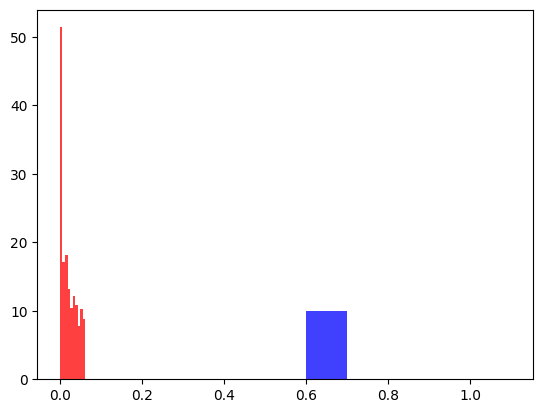

In [16]:
g3=[]
g1=[]
for i in range(1000):
    ### Copy your noisy version of the 3gate implementation here
    psi_f_3 = H@X@h@psi_i@epsilon_r()

    ### Copy your noisy version of the 1gate implementation here
    psi_f_1 = Z@psi_i@epsilon(e)

    #This will add the probability of |0> state into an array to plot!
    g3.append(prob(psi_f_3)[0,0])
    g1.append(prob(psi_f_1)[0,0])

plt.hist(g3, 10, density=True, facecolor='r', alpha=0.75)
plt.hist(g1, 10, density=True, facecolor='b', alpha=0.75)

### Running with a Realistic Noise Model

Let's put all this knowledge into a bit of practice.  In the previous lab, we discovered that an inefficient version of the $X$ gate was $HYHZSTSHXHTSXYXHZH$.  Alas, today quantum computers are just good enough that the error in this gate is hard to see compared to $X$.  Therefore we are going to consider the effect of noise on a different implementation of $X$: a deliberately bloated **102-gate** sequence that is *also* secretly just $X$ (you can check it, or trust me). You will see the full sequence built up in the code cell below.

To test this, we are going to try running a QisKit simulation with a noise model based on a real device.  This requires us to load a few packages

The packages this lab needs (`qiskit`, `qiskit-aer`, `pylatexenc`, `matplotlib`) are already installed in this environment, so there is nothing to install here.

*(On a fresh Colab runtime you would first run `%pip install qiskit qiskit-aer pylatexenc matplotlib`.)*

Now, let's import the various pieces of QisKit we need.

In [17]:
%pip install qiskit qiskit-aer

#This imports a parser (translator) from QASM code to QisKit
import qiskit.qasm2
#This imports the transpile function, which takes a circuit you create and maps it to a backend's availabe gates
from qiskit import transpile
#This imports the object QuantumCircuit that you build your circuit with
from qiskit import QuantumCircuit
#This imports a histogram function that maps nicely to the results of QisKit code
from qiskit.visualization import plot_histogram
#From Aer, we are going to import an object that will store our noisy simulators
from qiskit_aer import AerSimulator
#This imports a function that allows for passing options to a transpiler to do more elaborate transiplation
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

#From AER, we import a bunch of functions for defining types of noise
from qiskit_aer.noise import (
    NoiseModel,
    QuantumError,
    ReadoutError,
    depolarizing_error,
    pauli_error,
    thermal_relaxation_error,
)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 42.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 65.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 64.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.1 MB/s eta 0:00:00


In the next cells, we are going to define a "noise model" which defines the behaviour of our classical simulator of a digital quantum computer which will have 4 qubits.  To do this, we have to define some physical times $T_1,T_2$ which are related to how long a quantum state can persist.

$T_1$ is called the relaxation time - How long a $|{1}\rangle$ can persist before it deexcites to the ground state $|0\rangle$.  This is modelled as

$$\mathcal{N}\left[e^{-t/T_1}|1\rangle+(1-e^{-t/T_1})|0\rangle\right]$$

where I have used an overall normalization $\mathcal{N}$.

**Do you have any ideas what kind of physical processes could affect** $T_1$**?**

$T_2$ is called the dephasing time, and is defined analogously except in the $X$ basis, i.e. via
$$\mathcal{N}[e^{-t/T_2}|-\rangle+(1-e^{-t/T_2})|+\rangle]$$

For any given quantum computing hardware platform (and for any single qubit on them) there are different values that $T_1$ and $T_2$ can typically take.  Much engineering and material science goes into improving these properties.


For starters, lets assume that some quantum hardware exists with $T_1\approx 5\mu s$ and $T_2\approx7\mu s$.  For reasons related to gate times, we want these to be in units of nanoseconds.  Then we will consider that each qubit has $T_i$ that vary about this average by $1\mu s$.  In that case, we can use the following code to make an arrays for each:


In [18]:
# T1 and T2 values for qubits 0-3.  This function, normal(mu,sigma,N) gives N numbers randomly sampled
#from a normal distribution with mean mu and standard deviation sigma
T1s = np.random.normal(50e2, 10e2, 4) # Sampled from normal distribution with mean 5 microsec and 1 microsec standard deviation
T2s = np.random.normal(70e2, 10e2, 4)  # Sampled from normal distribution with mean 7 microsec and 1 microsec deviation

#Because physically T2s can't be much longer than T1s, we need to adjust in case the random numbers gave such situations
#by checking that random T2s <= T1s otherwise set T2 to 2*T1
T2s = np.array([min(T2s[j], 2 * T1s[j]) for j in range(4)])


These errors account for a qubit that is merely idling, in order to understand how these interact with gates and measurements, we need to account for the time a gate takes to run on the hardware.

For different hardware, there are different native gates.  For IBM devices, one common set is $U_{i}$ where $i=1,2,3$ correspond to arbitrary rotations around combinations of the $Z,X,Y$ axes.  These are related to the previously discussed $R_{i}(\theta)$.  

Additionally, performing a measurement on a quantum computer takes time, and can lead to infidelity as well.  One way in which they lead to error is that if too many gates are used, the total implementation time might rival $T_1,T_2$, leading to issues.

For each, we define a time it takes to run them (somewhat informed by IBM hardware).

In [19]:
# Instruction times (in nanoseconds)
time_u1 = 0    # virtual Z gate (in IBM hardware, you never need to actually run a Z gate, but it can be compiled alongside the U2 and U3)
time_u2 = 100  # (The time it takes for a single X by 90 pulse, which is taken to be the rough time of all U2)
time_u3 = 500 # (two X90 pulses which is roughly the time, alongside the virtual Z that gives the U3 gate)
time_measure = 1000 # Time taken to perform a measurement, taken to be 1 microsecond

# QuantumError objects which define the error channel related to a gate with a given T1 and T2 of device
errors_measure = [thermal_relaxation_error(t1, t2, time_measure)
                  for t1, t2 in zip(T1s, T2s)]
errors_u1  = [thermal_relaxation_error(t1, t2, time_u1)
              for t1, t2 in zip(T1s, T2s)]
errors_u2  = [thermal_relaxation_error(t1, t2, time_u2)
              for t1, t2 in zip(T1s, T2s)]
errors_u3  = [thermal_relaxation_error(t1, t2, time_u3)
              for t1, t2 in zip(T1s, T2s)]

# Here we define a noise model and add errors to it for all 4 qubits
noise_thermal = NoiseModel()

for j in range(4):
    noise_thermal.add_quantum_error(errors_measure[j], "measure", [j])
    noise_thermal.add_quantum_error(errors_u1[j], "u1", [j])
    noise_thermal.add_quantum_error(errors_u2[j], "u2", [j])
    noise_thermal.add_quantum_error(errors_u3[j], "u3", [j])

#Here we print information about this noise model that can be used later
print(noise_thermal)

NoiseModel:
  Basis gates: ['cx', 'id', 'rz', 'sx', 'u2', 'u3']
  Instructions with noise: ['u2', 'measure', 'u3']
  Qubits with noise: [0, 1, 2, 3]
  Specific qubit errors: [('measure', (0,)), ('measure', (1,)), ('measure', (2,)), ('measure', (3,)), ('u2', (0,)), ('u2', (1,)), ('u2', (2,)), ('u2', (3,)), ('u3', (0,)), ('u3', (1,)), ('u3', (2,)), ('u3', (3,))]


Here, we are going to import the circuit, and then draw it out.  Remember, we want to implement that same 102-gate, $X$-equivalent monster — its full gate sequence is the `gate_string` in the code below.

Here we build that circuit directly in the notebook from its list of gates, then draw it out. (Remember, it is just a very inefficient way of writing the single $X$ gate.)

In [20]:
%pip install pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 2.9 MB/s eta 0:00:00


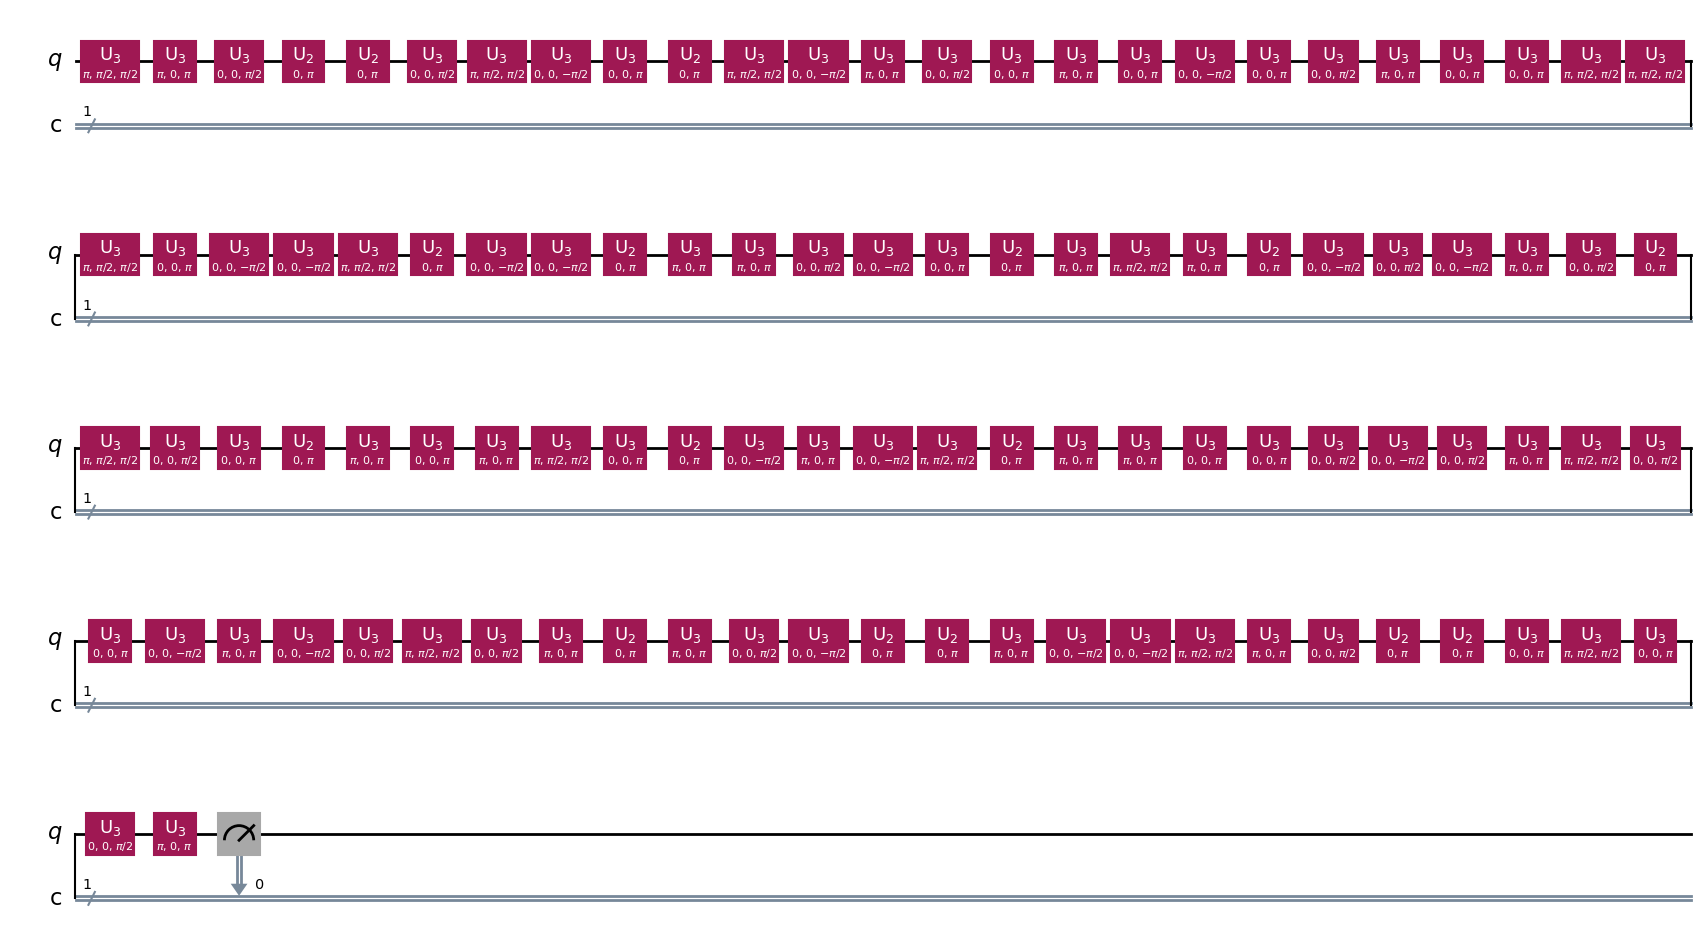

In [21]:


# Build the long, deliberately-inefficient circuit directly from its gate sequence.
# (Lowercase 's' is the S-dagger gate.)  You do not need to change this cell.
gate_string = "YXSHHSYsZHYsXSZXZsZSXZZYYYZssYHssHXXSsZHXYXHsSsXSHYSZHXZXYZHsXsYHXXZZSsSXYSZsXsSYSXHXSsHHXssYXSHHZYZSX"

qc = QuantumCircuit(1, 1)
apply = {'X': qc.x, 'Y': qc.y, 'Z': qc.z, 'H': qc.h, 'S': qc.s, 's': qc.sdg}
for g in gate_string:
    apply[g](0)
qc.measure(0, 0)

# Run the noisy simulation
sim_thermal = AerSimulator(noise_model=noise_thermal)

# Transpile circuit for noisy basis gates
passmanager = generate_preset_pass_manager(optimization_level=0, backend=sim_thermal)
circ_tthermal = passmanager.run(qc)
circ_tthermal.draw('mpl')

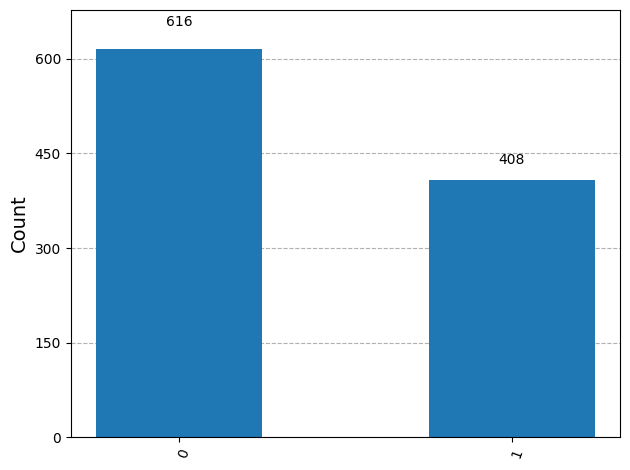

In [22]:
 # Run and get counts
result_thermal = sim_thermal.run(circ_tthermal).result()
counts_thermal = result_thermal.get_counts(0)

# Plot noisy output
plot_histogram(counts_thermal)

The results will be displayed as a histogram of all the measured results, and the number of times each event occurred.

- Find the **$|1\rangle$** bar and read off its count (the number of shots that landed in $|1\rangle$).

* <b>Dividing this number by the total number of shots (1024)</b>, you will get the measured probability $p_m$ of being found in the X state.

* How does your $p_m$ <b>compare with your theoretical expectation of $p_{theory}=1$</b>?  Is there clearly some type of noise affecting you?

So, to attach an uncertainty to the probability, we appeal to the "Binomial proportion confidence interval" (its got a wiki).  Without worrying too much about the details, insert your frequency into the line below, and extract both the mean probability and its 1$\sigma$ uncertainty.

In [23]:
# Read off the number of |1> counts from the histogram above.
frequency = 408

#probability of getting a |1> state
probability_measured = frequency/1024

#parameters needed for errorbars
z = 1-(1-0.68)/2.0
number_shots=1024

#compute the uncertainty
error_prob = z*np.sqrt(probability_measured*(1-probability_measured)/number_shots)

print("Mean probability: ", probability_measured," 1sigma Uncertainty: ",error_prob)

Mean probability:  0.3984375  1sigma Uncertainty:  0.012851380691865597


Presumably, you have established that something is causing error in your results.  Lets see if we can narrow it down.

* In the cell below <b>Create a new circuit that does the optimized single $X$ circuit</b>
* Run this new code with <b> the same noise model</b>, and record your frequency below


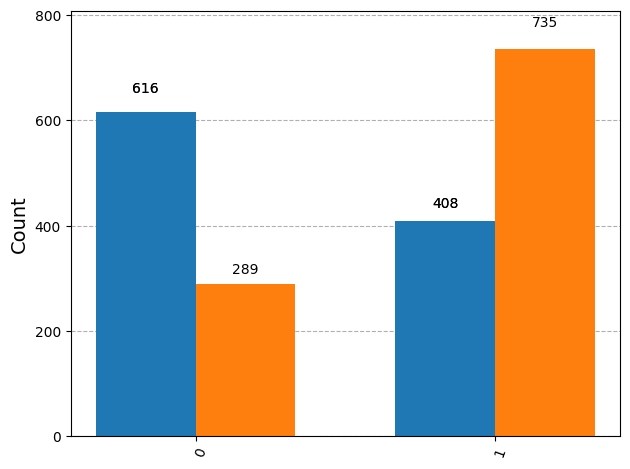

In [24]:
#Implement a 1 qubit, 1 bit Quantum Circuit which has an X gate, and is then measured
# your code here
qc2 = QuantumCircuit(1, 1)
qc2.x(0)
qc2.measure(0, 0)

# Run the noisy simulation
sim_thermal = AerSimulator(noise_model=noise_thermal)

 # Transpile circuit for noisy basis gates
passmanager = generate_preset_pass_manager(optimization_level=0, backend=sim_thermal)
circ_tthermal2 = passmanager.run(qc2)

# Run and get counts
result_thermal2 = sim_thermal.run(circ_tthermal2).result()
counts_thermal2 = result_thermal2.get_counts(0)

# Plot noisy output
plot_histogram([counts_thermal,counts_thermal2])

In the cell below, record your new frequency of $|1\rangle$

* Does your probability <b>differ greatly from the results from the longer circuit</b>? Does it seem that the gate fidelity is the limiting error?

In [25]:
# Read off the number of |1> counts for the single-X circuit.
frequency = 735

#probability of getting a |1> state
probability_measured = frequency/1024

#parameters needed for errorbars
z = 1-(1-0.68)/2.0
number_shots=1024

#compute the uncertainty
error_prob = z*np.sqrt(probability_measured*(1-probability_measured)/number_shots)

print("Mean probability: ", probability_measured," 1sigma Uncertainty: ",error_prob)

Mean probability:  0.7177734375  1sigma Uncertainty:  0.011814679421597089


Now that you have a taste of how better circuit can give the same result with less error, lets see how better computers can achieve a similar improvement.

To do this, remember that one source of noise is that if you use too many gates, and the different gates have different times they require to run.

* As a first step, let's see how many of the various gates get called in each circuit.  To do this, you can <b> print the command [CIRCUIT].count_ops() </b>

* How many u1,u2,u3, and measurements do you need?

In [26]:
print(circ_tthermal.count_ops())
print(circ_tthermal2.count_ops())

OrderedDict({'u3': 86, 'u2': 16, 'measure': 1})
OrderedDict({'u3': 1, 'measure': 1})


In the next cell, I have defined for you a function, your_noise(Nq,T1,dT1,T2,dT2,tu1,tu2,tu3,tmeasure), which can be used to redefine a new "computer" with different physical parameters related to its ability to compute.

Take a look at it, and then proceed.

In [27]:
def your_noise(Nq,T1,dT1,T2,dT2,tu1,tu2,tu3,tmeasure):

# T1 and T2 values for qubits 0-3
  T1s = np.random.normal(T1, dT1, Nq)
  T2s = np.random.normal(T2, dT2, Nq)

# Truncate random T2s <= T1s
  T2s = np.array([min(T2s[j], 2 * T1s[j]) for j in range(Nq)])

# Instruction times (in nanoseconds)
  time_u1 = tu1    # virtual gate
  time_u2 = tu2  # (single X90 pulse)
  time_u3 = tu3 # (two X90 pulses)
  time_measure = tmeasure # 1 microsecond

# QuantumError objects
  errors_measure = [thermal_relaxation_error(t1, t2, time_measure)
                  for t1, t2 in zip(T1s, T2s)]
  errors_u1  = [thermal_relaxation_error(t1, t2, time_u1)
              for t1, t2 in zip(T1s, T2s)]
  errors_u2  = [thermal_relaxation_error(t1, t2, time_u2)
              for t1, t2 in zip(T1s, T2s)]
  errors_u3  = [thermal_relaxation_error(t1, t2, time_u3)
              for t1, t2 in zip(T1s, T2s)]

# Add errors to noise model
  noise_model = NoiseModel()
  for j in range(Nq):
      noise_model.add_quantum_error(errors_measure[j], "measure", [j])
      noise_model.add_quantum_error(errors_u1[j], "u1", [j])
      noise_model.add_quantum_error(errors_u2[j], "u2", [j])
      noise_model.add_quantum_error(errors_u3[j], "u3", [j])

  return noise_model

In the next cell, you should see that I have collected the entire code necessary to resimulate the $X$ gate circuit with different "computers" with different noise models.  

In the second line, you can change the various parameters of the computer, and see how they affect the fidelity of your results.  Can you design a computer with above 90% probability in the $|1\rangle$ state?

Mean probability:  0.999 ± 0.001


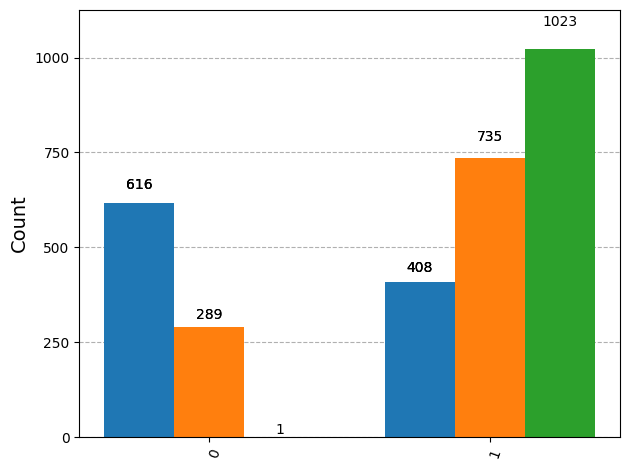

In [30]:
# Let's design a high-quality computer to achieve >90% probability
your_noise_model = your_noise(4, 100000, 10000, 120000, 10000, 1, 10, 50, 100)

# Run the noisy simulation
sim_thermal2 = AerSimulator(noise_model=your_noise_model)

# Transpile circuit for noisy basis gates
passmanager = generate_preset_pass_manager(optimization_level=0, backend=sim_thermal2)
circ_tthermal3 = passmanager.run(qc2)

# Run and get counts
result_thermal3 = sim_thermal2.run(circ_tthermal3).result()
counts_thermal3 = result_thermal3.get_counts(0)

#compute the uncertainty
error_prob = (1-(1-0.68)/2.0)*np.sqrt(result_thermal3.get_counts(0)["1"]/1024*(1-result_thermal3.get_counts(0)["1"]/1024)/1024)
print("Mean probability: ", np.round(result_thermal3.get_counts(0)["1"]/1024,3),"±",np.round(max(error_prob,0.001),3))

# Plot noisy output
plot_histogram([counts_thermal,counts_thermal2,counts_thermal3])

Before you pat yourself on the back too much, remember that reducing noise -- building a better quantum computer -- doesn't come for free.  It costs ALOT of money to improve the properties.  You might redo the circuitry, but a new fridge to keep things colder, you might use more expensive hardware, you might just pay better engineers to run the thing.

In the next cell, I have defined a random, parametric estimate of the relative cost of computers, but don't take this seriously as the true cost estimate.  

In [32]:
def device_cost(Nq,T1,dT1,T2,dT2,tu1,tu2,tu3,tmeasure):
  print("$",np.round(121.31989*max(2,Nq)**2*(max(T1,50e2)/40e2)**1.09*(max(T2,70e2)/10e3)**1.09*(2+(1+np.log(1+tu1))**-1.04)*(2.72+(1+np.log(1+tu2))**-1.12)*(6.2+(1+np.log(1+tu3))**-1.04)*(2.3+(1+np.log((1+tmeasure)))**-1.01)*np.exp((-dT1/T1)+(-dT2/T2)),2))

* Using this function, **compare your computer's price to that of the original one?**

* By changing the physical inputs in the previous cell, **how cheap can you design a computer with 90% fidelity?**


In [37]:
# Cost of the original computer
device_cost(4, 50e2, 10e2, 70e2, 10e2, 1, 100, 500, 1000)

device_cost(4, 12000, 1000, 15000, 1000, 1, 80, 300, 800)

$ 134940.23
$ 980533.08
